In [1]:
pip install -U mplhep

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import coffea.util
import matplotlib.pyplot as plt
import yaml
import awkward as ak

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.studyingDYjetsWithData import tools
from sidm.studies.cosmicVeto import functions
utilities.set_plot_style()
%matplotlib inline

In [3]:
ratio = 6.616 /59.83

In [4]:
data = functions.get_data_files()
data = [x for x in data if "C" in x]
channel_name  = "cr_1egmOr1mu_lj_cosmic_veto_highPtLj"


In [5]:
DY= [
      "DYJetsToLL_M10to50",
       "DYJetsToLL_M50",
]
folder_name = f"OutputFiles/{channel_name}"
sum_data_all = utilities.sum_hist(data, folder_name)
summed_DY  = utilities.sum_hist(DY, folder_name)

In [7]:
list(sum_data_all.keys())

['muon_muon_invmass',
 'muon_muon_invmass_highRange',
 'mulj_egmlj_invmass',
 'lj_lj_invmass',
 'muon_n',
 'electron_n',
 'dsaMuon_n',
 'photon_n',
 'mu_lj_mass',
 'egm_lj_mass',
 'mu0_mu1_dphi_invMass',
 'mu_mu_dphi_invMass',
 'mu_mu_dphi',
 'mu_mu_inv_mass',
 'jets_n',
 'jets_pt']

muon_muon_invmass
muon_muon_invmass_highRange


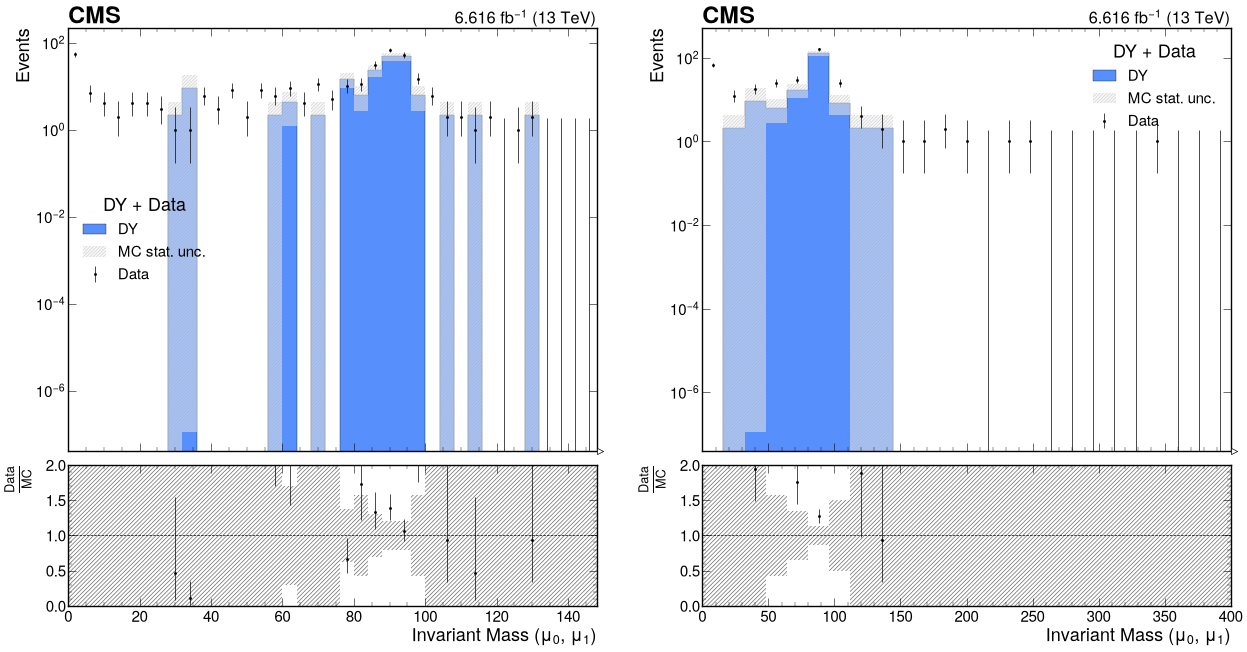

In [15]:
histogram_list = ['muon_muon_invmass',
 'muon_muon_invmass_highRange',

]

tools.plot_DataMC(
    histogram_list=histogram_list[:5],
    channel_name=channel_name,
    summed_DY=summed_DY,
    summed_data=sum_data_all,
    ratio=ratio,
    binning=4j,
    ranges=None,
    file_name="DY_Data_2LJ",
    title="DY + Data"
)

muon_n
electron_n
dsaMuon_n
photon_n


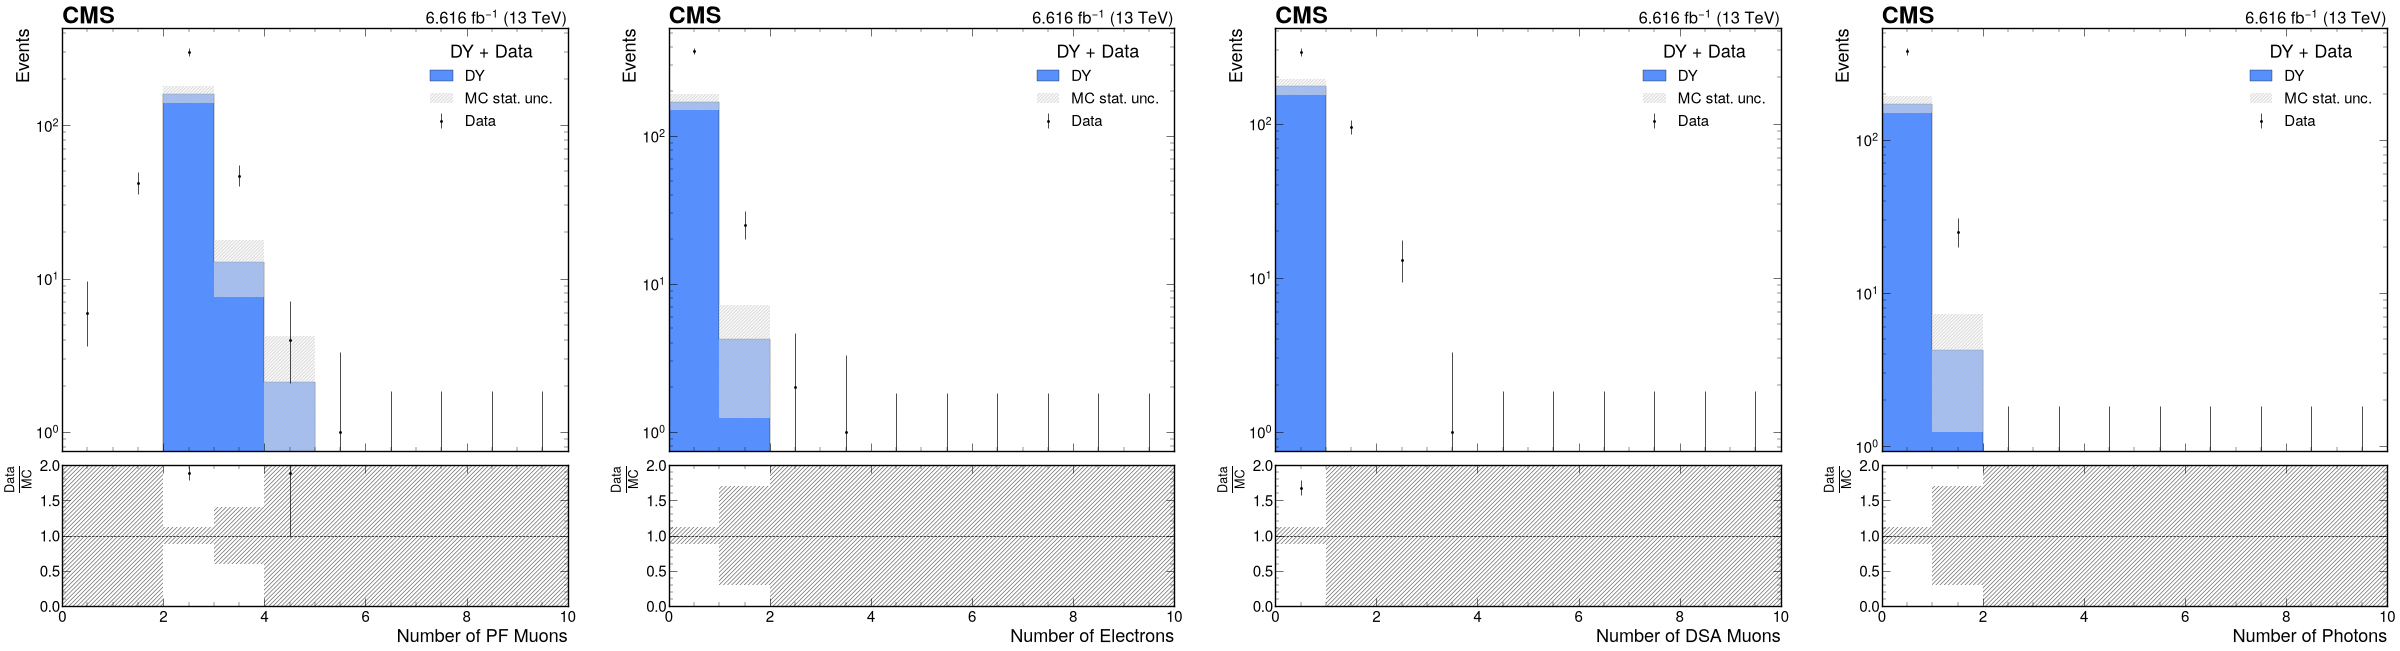

In [10]:
histogram_list = [ 'muon_n',
 'electron_n',
 'dsaMuon_n',
 'photon_n',]
tools.plot_DataMC(
    histogram_list=histogram_list[:5],
    channel_name=channel_name,
    summed_DY=summed_DY,
    summed_data=sum_data_all,
    ratio=ratio,
    binning=1j,
    ranges=None,
    file_name="DY_Data_2LJ",
    title="DY + Data"
)

mu_lj_mass
mu_mu_inv_mass


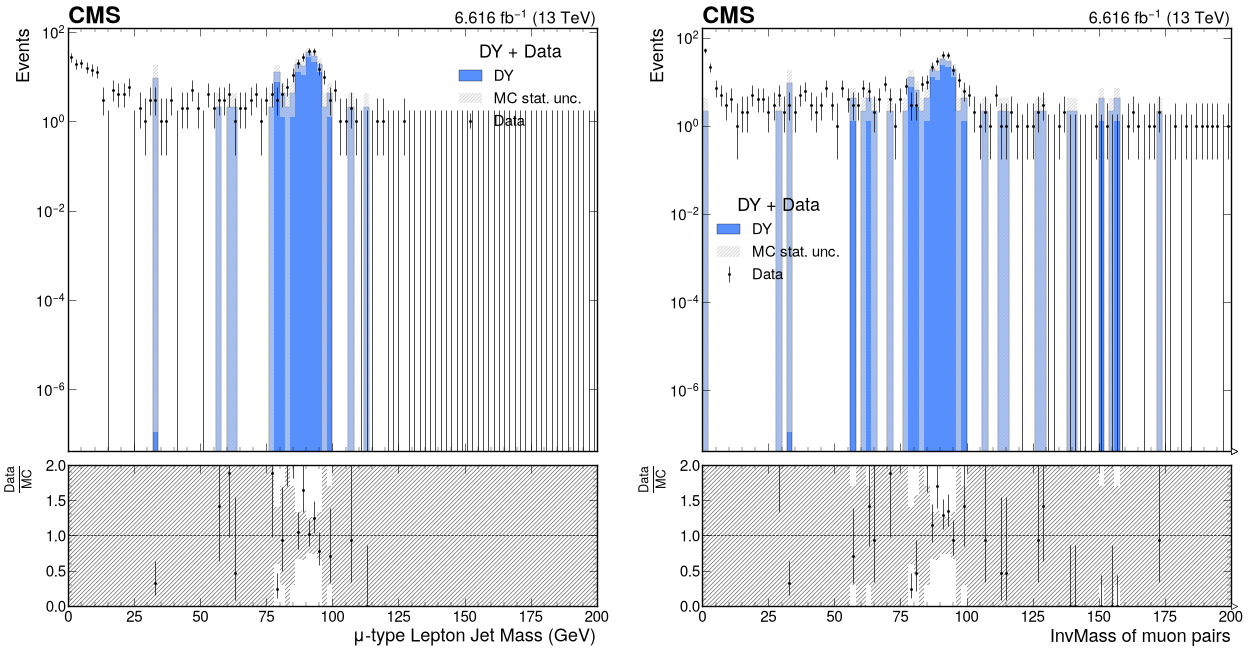

In [26]:
histogram_list = [
     'mu_lj_mass',
 # 'mu_mu_dphi',
 'mu_mu_inv_mass',
]
tools.plot_DataMC(
    histogram_list=histogram_list,
    channel_name=channel_name,
    summed_DY=summed_DY,
    summed_data=sum_data_all,
    ratio=ratio,
    binning=1j,
    ranges=None,
    file_name="DY_Data_2LJ",
    title="DY + Data"
)

jets_n
jets_pt


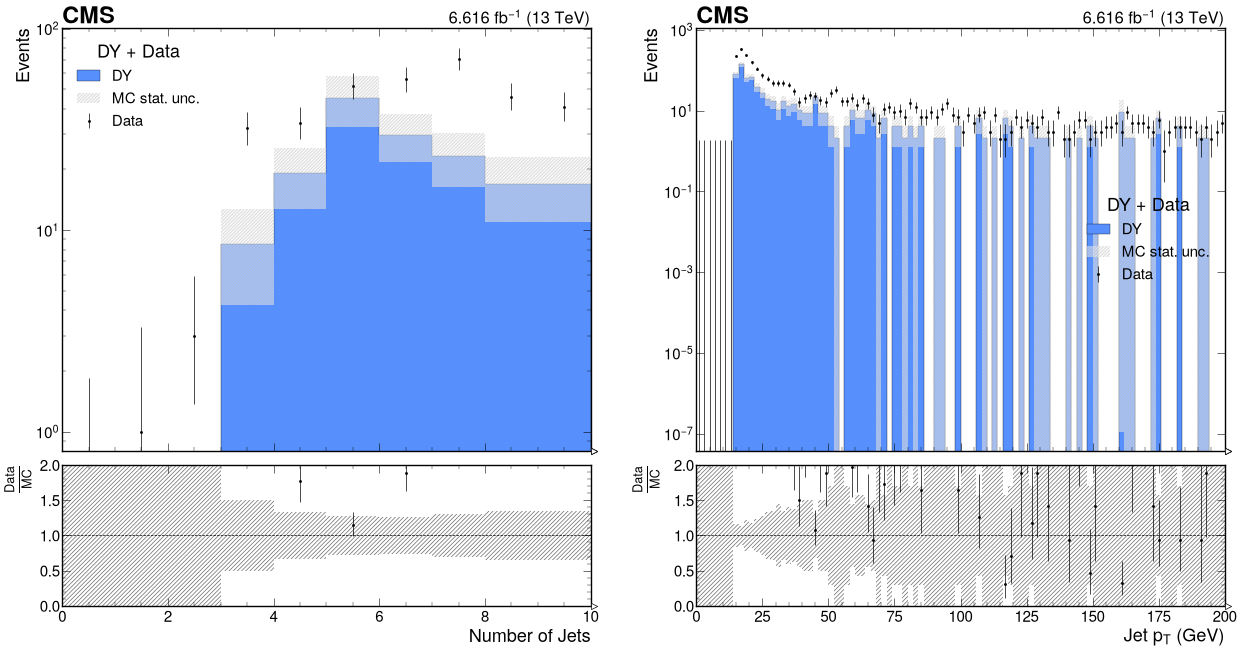

In [12]:
histogram_list = [

 'jets_n',
 'jets_pt'
]

tools.plot_DataMC(
    histogram_list=histogram_list[:5],
    channel_name=channel_name,
    summed_DY=summed_DY,
    summed_data=sum_data_all,
    ratio=ratio,
    binning=1j,
    ranges=None,
    file_name="DY_Data_2LJ",
    title="DY + Data"
)

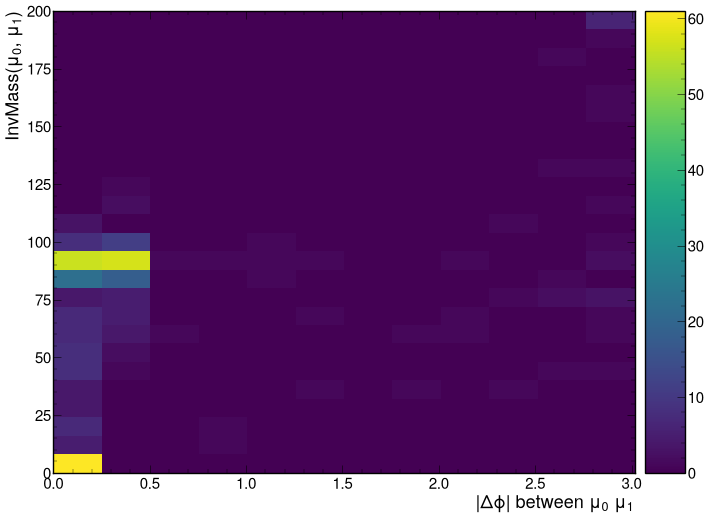

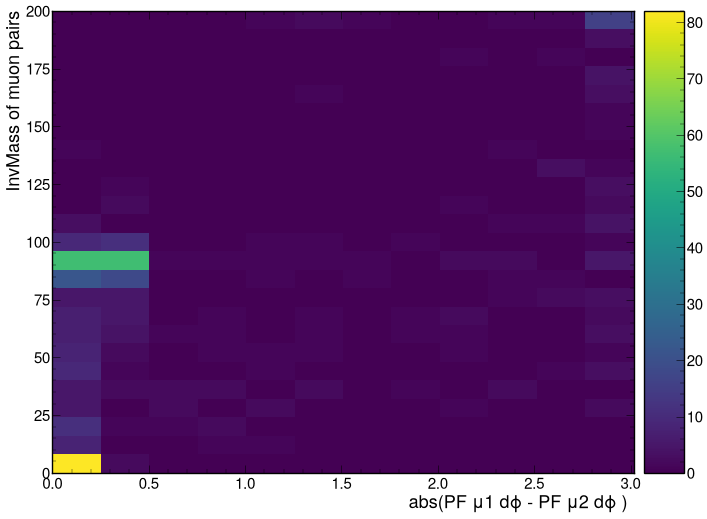

In [25]:
histogram_list = [
     'mu0_mu1_dphi_invMass',
 'mu_mu_dphi_invMass',
]

for j, histogram_name in enumerate(histogram_list):
    try:
        histogram = sum_data_all[histogram_name][channel_name,:]
    except:
        try:
            histogram = sum_data_all[histogram_name][channel_name,::4j,::4j]
        except:  
            continue
    plt.figure(figsize=(15, 12))
    utilities.plot(histogram, skip_label = True)
    plt.show()
    plt.close()


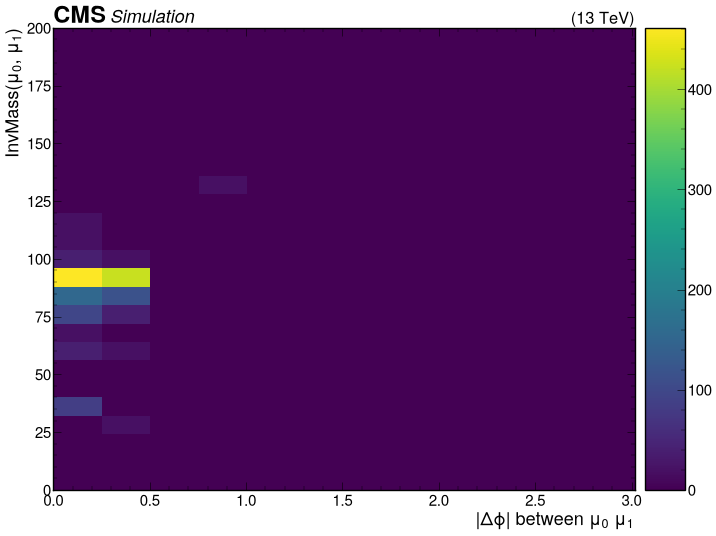

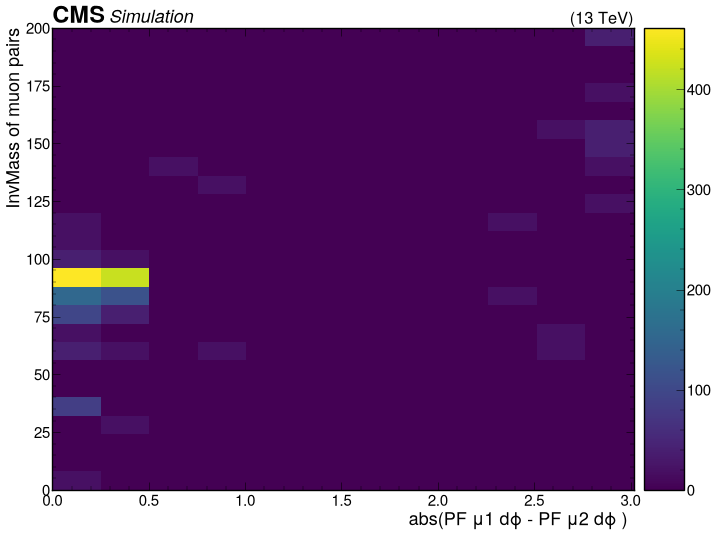

In [17]:
histogram_list = [
     'mu0_mu1_dphi_invMass',
 'mu_mu_dphi_invMass',
]

for j, histogram_name in enumerate(histogram_list):
    try:
        histogram = summed_DY[histogram_name][channel_name,:]
    except:
        try:
            histogram = summed_DY[histogram_name][channel_name,::4j,::4j]
        except:  
            continue
    plt.figure(figsize=(15, 12))
    utilities.plot(histogram)
    plt.show()
    plt.close()